**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**20 | HARTH Research Evidence Consolidation and Provenance Audit**

![Stage 20 scientific workflow](../../images/20_workflow.svg)

**Objective:** Consolidate the saved scientific evidence from HARTH Stages 01–19, inspect historical execution records and distinguish comparable from non-comparable experimental results.

**Dataset:** The version-controlled HARTH v2.0 research notebooks, source-code artefacts and experiment register; raw recordings are not reloaded.

**Notebook Scope:** Inventory the first 20 Notebooks as a historical research checkpoint, review the 19-stage evidence register and document evaluation boundaries, class coverage, confidence results and limitations. Numerical findings are transcribed from earlier saved outputs, not recomputed. Reserved Test participants S023 and S032 had been inspected descriptively before their later protected role and must not be described as strictly unseen.

**Evidence basis:** Saved notebook code and outputs are the primary evidence, supported by reusable functions, tests, protocol documents and the research register. A recorded Quality Gate message does not establish independent generalisation.

**00. Colab Repository Setup**

In [ ]:
# ======================== 00. Colab Repository Setup =========================

# ------------------------- Repository Configuration --------------------------
from pathlib import Path

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")

# ------------------------ Clone Repository if Missing ------------------------
%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ------------------------------ Open Repository ------------------------------
%cd {repo_path}


**01. Imports and Evidence-Audit Utilities**

In [1]:
# ================= 01. Imports and Evidence-Audit Utilities ==================

from pathlib import Path

# ----------------------------- Standard Library ------------------------------
import sys

# ------------------ Scientific Computing and Visualisation -------------------
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

from IPython.display import display

# ---------------- Repository Discovery and Evidence Utilities ----------------
root = Path.cwd().resolve()

while not (root / "python_modules/core/notebook_evidence.py").is_file():
    if root == root.parent:
        raise RuntimeError("Open this notebook inside human-movement-intelligence.")
    root = root.parent

sys.path.insert(0, str(root / "python_modules"))

# ------------------------- Read-Only Evidence Module -------------------------
from core.notebook_evidence import (
    collect_notebook_inventory, validate_evidence_register,
    extract_saved_output_text,
)

# -------------------- Notebook and Register Source Paths ---------------------
notebook_dir = root / "wearable_activity_recognition/code/notebooks"

register_path = root / "wearable_activity_recognition/evidence/stage_01_19_evidence_register.csv"

# ---------------- Research Repository and Evidence Locations -----------------
print("Repository:", root)

print("Source notebooks:", notebook_dir)

print("Evidence register:", register_path)


Repository: D:\human-movement-intelligence
Source notebooks: D:\human-movement-intelligence\studies\wearable_activity_recognition\notebooks
Evidence register: D:\human-movement-intelligence\studies\wearable_activity_recognition\evidence\stage_01_19_evidence_register.csv


**02. Inventory Historical Saved Notebook Evidence**

Inspect saved code-cell outputs, errors, and recorded metadata for the original Stages 01–20. This is an archival snapshot of that point in the project, not an outstanding action list for the completed 27-stage study.

In [2]:
# ================= 02. Audit Saved Notebook Execution States =================

# ---------------------- Saved-Cell Execution Inventory -----------------------
inventory = collect_notebook_inventory(notebook_dir)  # Read saved notebook state without executing cells.

# ------------------- Saved Outputs and Execution Evidence --------------------
display(inventory[[
    "stage", "notebook", "code_cells", "executed_code_cells",
    "cells_with_outputs", "unexecuted_code_cells",
    "saved_error_count", "saved_pass_marker",
]])

# ----------------------- Incomplete-Execution Summary ------------------------
print("Stages inventoried:", len(inventory))

print("Saved errors:", int(inventory["saved_error_count"].sum()))

print("Stages with incomplete execution counts:",
      inventory.loc[inventory["unexecuted_code_cells"] > 0, "stage"].tolist())


,stage,notebook,code_cells,executed_code_cells,cells_with_outputs,unexecuted_code_cells,saved_error_count,saved_pass_marker
0,1,01_data_loading_and_inspection.ipynb,7,5,7,2,0,False
1,2,02_signal_preprocessing_and_windowing.ipynb,7,6,7,1,0,True
2,3,03_statistical_feature_engineering.ipynb,7,4,7,3,0,True
3,4,04_subject_independent_splitting.ipynb,6,2,6,4,0,True
4,5,05_classical_ml_baselines.ipynb,8,6,8,2,0,True
5,6,06_subject_level_cross_validation.ipynb,7,5,7,2,0,True
6,7,07_expanded_subject_evaluation.ipynb,7,6,7,1,0,True
7,8,08_full_development_audit.ipynb,6,6,6,0,0,True
8,9,09_full_development_cross_validation.ipynb,8,8,8,0,0,True
9,10,10_pytorch_temporal_cnn.ipynb,8,8,8,0,0,True


Stages inventoried: 27
Saved errors: 0
Stages with incomplete execution counts: [1, 2, 3, 4, 5, 6, 7, 20, 21, 24, 27]


**03. Validate the Nineteen-Stage Evidence Register**

Check that the register links Stages 01–19 to their research questions, Notebook sources, experimental scopes, principal recorded observations and interpretation boundaries. Because protocols differ, the register is not a single comparable leaderboard. Stage 20 audits historical evidence rather than adding a twentieth training experiment.

In [3]:
# ============= 03. Validate the Source-Linked Evidence Register ==============

# ----------------------- Source-Linked Register Import -----------------------
register = pd.read_csv(register_path, encoding="utf-8")

# ---------------------- Register and Notebook Alignment ----------------------
evidence = validate_evidence_register(inventory, register)  # Cross-check the register against saved notebook evidence.

assert evidence["stage"].tolist() == list(range(1, 20))

# ----------------- Provenance and Scope of Research Evidence -----------------
display(evidence[[
    "stage", "research_question", "protocol",
    "key_evidence", "limitations",
]])

print("Evidence register and 19 source notebooks: ALIGNED")


,stage,research_question,protocol,key_evidence,limitations
0,1,HARTH source inspection,Single participant S023,137646 source rows; six accelerometer channels,"Single-participant exploration, not validation"
1,2,Time-safe windowing,S023; 100 samples; step 50,"2567 retained windows, 184 candidates rejected",Only one subject
2,3,Statistical feature extraction,S023; 5 features per 6 axes,2567 x 30 feature matrix,No model fitting
3,4,Participant-disjoint split,8 subjects; source activity audit,4/2/2 people in Train/Validation/Test; raw unk...,Undocumented classes not valid prediction labels
4,5,Initial classical baselines,6 development subjects; 2 reserved,Logistic regression Validation Macro F1 0.8343...,Single development Validation split
5,6,Six-person grouped CV,"6 development people, three folds",Logistic regression mean Macro F1 0.7434; RF 0...,Development-only CV; uneven activity coverage
6,7,Expanded grouped CV,"10 development subjects, five folds",RF Macro F1 0.7235; LR 0.7188,Small development subset
7,8,Full development class audit,"29 development people, five proposed folds",132397 eligible windows; 30 features; eight cl...,No classifier trained
8,9,Full-development classical CV,"29 development people, five folds",RF mean Macro F1 0.8339; LR 0.7710,Different source-window volume from later CNN ...
9,10,Raw temporal CNN pilot,"29 development subjects, <=500 windows/person",14201 windows; CNN Validation Macro F1 0.6659,Single development split; model not matched to...


Evidence register and 19 source notebooks: ALIGNED


**04. Document Source Cohorts and Test Boundaries**

HARTH v2.0 provides six lower-back and thigh acceleration channels at a nominal 50 Hz. The study uses label-pure, two-second windows with a 50-sample stride and timestamp-continuity checks. Supervised models consider documented activity codes 1–8; excluded cycling and undocumented codes are counted after windowing, not reassigned.

The full 29-person Development cohort contains 132,397 eligible windows. Bounded studies use 14,201 base-500 windows, with 28,201 rows under the nested 1,000-cap policy. S023 and S032 were reserved for later evaluation after earlier descriptive inspection, so strict preregistered Test blindness cannot be claimed.

In [4]:
# ============== 04. Trace Source Cohort and Reserved Test Roles ==============

# ------------------------- Source Cohort Definitions -------------------------
dataset_facts = pd.DataFrame([
    {"cohort": "Full development, 29 people",
     "eligible_windows": 132397, "channels": 6,
     "time_steps": 100, "source_stage": 8},
    {"cohort": "Original 500-cap development sample",
     "eligible_windows": 14201, "channels": 6,
     "time_steps": 100, "source_stage": 10},
    {"cohort": "Nested 1000-cap development sample",
     "eligible_windows": 28201, "channels": 6,
     "time_steps": 100, "source_stage": 15},
])

# ------------------------- Documented Window Counts --------------------------
display(dataset_facts)

assert (dataset_facts["eligible_windows"] > 0).all()

# -------------- Reserved Test Participants and Historical Scope --------------
print("Reserved original Test IDs: S023, S032")

print("Reserved from later model development: YES")

print("Never previously inspected: NO")


,cohort,eligible_windows,channels,time_steps,source_stage
0,"Full development, 29 people",132397,6,100,8
1,Original 500-cap development sample,14201,6,100,10
2,Nested 1000-cap development sample,28201,6,100,15


Reserved original Test IDs: S023, S032
Reserved from later model development: YES
Never previously inspected: NO


**05. Distinguish Matched and Unmatched Experimental Protocols**

Notebooks 11–12 share bounded source windows and a single Train/Validation split; Notebook 13 uses matched three-fold comparisons. Notebooks 15–16 use nested Train cohorts with fixed Validation rows, while Notebook 17 equalises optimiser-update counts.

The full-cohort, five-fold classical comparison in Notebook 09 is not directly comparable to the bounded CNN pilot in Notebook 10. Notebook 19 introduces an additional Calibration group and therefore differs from Notebook 18. Interpret metrics only within appropriately matched protocols.

In [5]:
# ============== 05. Distinguish Matched and Unmatched Protocols ==============

# ------------------- Matched and Unmatched Study Protocols -------------------
comparison_map = pd.DataFrame([
    {"stages": "09 vs 10", "matched": False,
     "reason": "Full 132,397-window, 5-fold classical CV vs capped 14,201-window, one-split CNN"},
    {"stages": "11–12", "matched": True,
     "reason": "Identical original 500-cap source windows and six-person Validation split"},
    {"stages": "13", "matched": True,
     "reason": "Three classifiers evaluated on the same 3 GroupKFold assignments and 500-cap rows"},
    {"stages": "15", "matched": True,
     "reason": "Strictly nested Train windows; six-person Validation source rows fixed"},
    {"stages": "16", "matched": True,
     "reason": "Four training-size/model conditions use identical base Validation rows within folds"},
    {"stages": "17", "matched": True,
     "reason": "Two nested Train conditions, same 400 updates and same held-out people/rows"},
    {"stages": "18 vs 19", "matched": False,
     "reason": "Stage 19 withholds separate Calibration subjects from CNN Train"},
])

display(comparison_map)


,stages,matched,reason
0,09 vs 10,False,"Full 132,397-window, 5-fold classical CV vs ca..."
1,11–12,True,Identical original 500-cap source windows and ...
2,13,True,Three classifiers evaluated on the same 3 Grou...
3,15,True,Strictly nested Train windows; six-person Vali...
4,16,True,Four training-size/model conditions use identi...
5,17,True,"Two nested Train conditions, same 400 updates ..."
6,18 vs 19,False,Stage 19 withholds separate Calibration subjec...


**06. Consolidate Source-Reported Development Metrics**

Present the recorded model scores as attributed research evidence, without rerunning experiments or pooling incompatible protocols. Use fixed eight-class Macro F1 where specified, and preserve differences in source sampling, participant folds, model representations and training budgets.

,stage,protocol,model,mean_macro_f1
0,9,"full 29-person, 5 folds, 132397 windows",Random Forest,0.8339
1,9,"full 29-person, 5 folds, 132397 windows",Logistic Regression,0.7710
2,13,"bounded 500-cap, 3 folds",Random Forest,0.8076
3,13,"bounded 500-cap, 3 folds",Standard CNN,0.6301
4,13,"bounded 500-cap, 3 folds",Weighted CNN,0.7834
5,16,"nested Train, matched 500-cap Validation, 3 fo...",RF 500,0.8076
6,16,"nested Train, matched 500-cap Validation, 3 fo...",RF 1000,0.8097
7,16,"nested Train, matched 500-cap Validation, 3 fo...",Weighted CNN 500,0.7834
8,16,"nested Train, matched 500-cap Validation, 3 fo...",Weighted CNN 1000,0.7962
9,17,"nested Train, matched 500-cap Validation, 3 fo...",Weighted CNN 500,0.7746


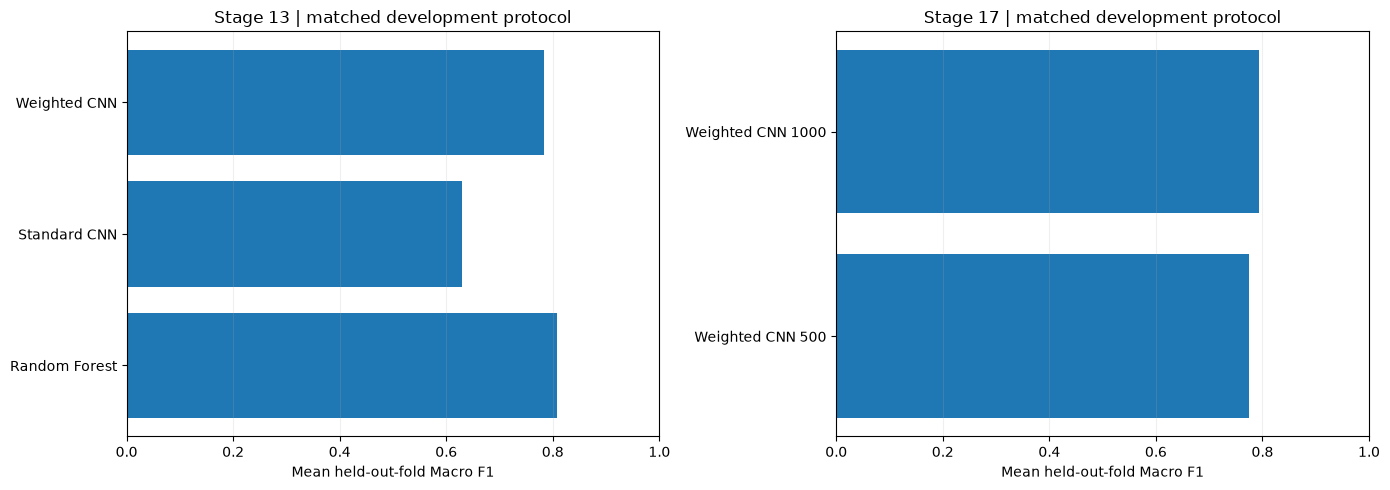

In [6]:
# ============= 06. Consolidate Verified Development Model Scores =============

# ------------------- Recorded Development Macro F1 Results -------------------
grouped_scores = pd.DataFrame([
    {"stage": 9, "protocol": "full 29-person, 5 folds, 132397 windows",
     "model": "Random Forest", "mean_macro_f1": 0.8339},
    {"stage": 9, "protocol": "full 29-person, 5 folds, 132397 windows",
     "model": "Logistic Regression", "mean_macro_f1": 0.7710},
    {"stage": 13, "protocol": "bounded 500-cap, 3 folds",
     "model": "Random Forest", "mean_macro_f1": 0.8076},
    {"stage": 13, "protocol": "bounded 500-cap, 3 folds",
     "model": "Standard CNN", "mean_macro_f1": 0.6301},
    {"stage": 13, "protocol": "bounded 500-cap, 3 folds",
     "model": "Weighted CNN", "mean_macro_f1": 0.7834},
    {"stage": 16, "protocol": "nested Train, matched 500-cap Validation, 3 folds, fixed epochs",
     "model": "RF 500", "mean_macro_f1": 0.8076},
    {"stage": 16, "protocol": "nested Train, matched 500-cap Validation, 3 folds, fixed epochs",
     "model": "RF 1000", "mean_macro_f1": 0.8097},
    {"stage": 16, "protocol": "nested Train, matched 500-cap Validation, 3 folds, fixed epochs",
     "model": "Weighted CNN 500", "mean_macro_f1": 0.7834},
    {"stage": 16, "protocol": "nested Train, matched 500-cap Validation, 3 folds, fixed epochs",
     "model": "Weighted CNN 1000", "mean_macro_f1": 0.7962},
    {"stage": 17, "protocol": "nested Train, matched 500-cap Validation, 3 folds, fixed 400 updates",
     "model": "Weighted CNN 500", "mean_macro_f1": 0.7746},
    {"stage": 17, "protocol": "nested Train, matched 500-cap Validation, 3 folds, fixed 400 updates",
     "model": "Weighted CNN 1000", "mean_macro_f1": 0.7927},
])

# ------------------------- Source-Linked Score Table -------------------------
display(grouped_scores)

# --------------------- Within-Protocol Score Comparisons ---------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, stage in zip(axes, [13, 17]):
    group = grouped_scores[grouped_scores["stage"] == stage]
    ax.barh(group["model"], group["mean_macro_f1"])
    ax.set(title=f"Stage {stage} | matched development protocol",
           xlabel="Mean held-out-fold Macro F1", xlim=(0, 1))
    ax.grid(axis="x", alpha=0.2)

fig.tight_layout()
plt.show()


**07. Audit Minority-Class Sampling and Performance**

The full Development cohort contains 1,946 Shuffling windows. The original 500-cap policy retained 219, while a separately sampled 1,000-cap policy retained 386. The strictly nested 1,000-cap selection used in later experiments differs from the independent 1,000-point sampling policy in Notebook 14.

In Notebook 13, pooled Shuffling F1 was 0.4957 for Random Forest and 0.1345 for weighted CNN. Notebook 16 recorded 0.2513 for weighted CNN 1000 on the held-out base-window set. These comparisons are exploratory and do not isolate a causal effect of training-data size.

,activity,full,cap_500,cap_1000_independent,retained_500_pct,retained_1000_pct
0,Shuffling,1946,219,386,11.25,19.84
1,Stairs ascending,1332,192,375,14.41,28.15
2,Stairs descending,1066,182,348,17.07,32.65


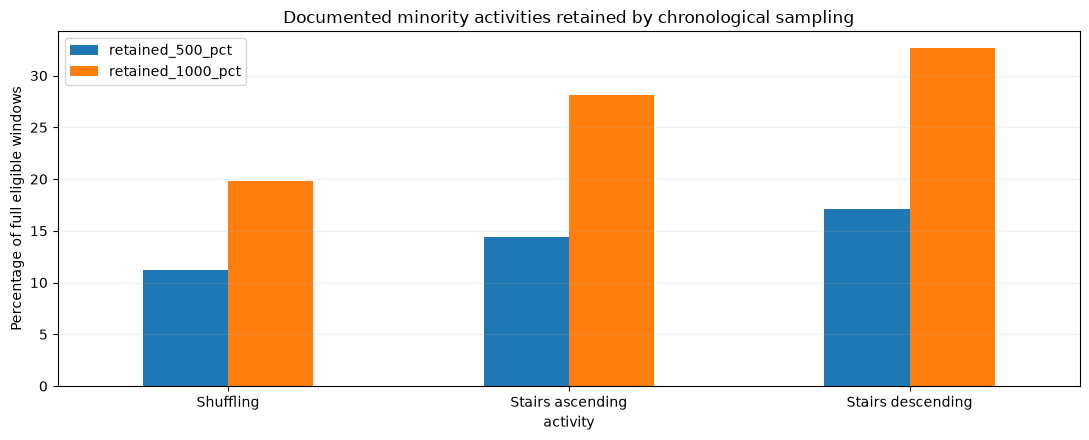

In [7]:
# ================ 07. Audit Minority-Class Sampling Retention ================

# ----------------------- Minority-Class Source Support -----------------------
rare_support = pd.DataFrame([
    {"activity": "Shuffling", "full": 1946, "cap_500": 219, "cap_1000_independent": 386},
    {"activity": "Stairs ascending", "full": 1332, "cap_500": 192, "cap_1000_independent": 375},
    {"activity": "Stairs descending", "full": 1066, "cap_500": 182, "cap_1000_independent": 348},
])

# ------------------------ Per-Cap Activity Retention -------------------------
rare_support["retained_500_pct"] = rare_support["cap_500"] / rare_support["full"] * 100

rare_support["retained_1000_pct"] = rare_support["cap_1000_independent"] / rare_support["full"] * 100

# -------------------- Minority Sampling Retention Figure ---------------------
display(rare_support.round(2))

ax = rare_support.set_index("activity")[["retained_500_pct", "retained_1000_pct"]].plot(
    kind="bar", figsize=(11, 4.5), rot=0)
ax.set(title="Documented minority activities retained by chronological sampling",
       ylabel="Percentage of full eligible windows")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


**08. Compare Uncalibrated Confidence and Temperature Scaling**

Notebook 18 examined uncalibrated out-of-fold confidence and identified 40 incorrect predictions with maximum softmax of at least 0.90. Notebook 19 used separate Train, Calibration and Validation participants. The table below retains the Stage 19 calibration figures recorded in this historical evidence snapshot; they are not recalculated from the current Notebook 19. The later saved execution of Notebook 19 reports different fold means. Consult its saved outputs for the current numerical values rather than treating this historical table as the latest result.

Two folds improved NLL and Brier; one worsened. Scalar temperature scaling leaves top-1 predictions unchanged and cannot be described as improving minority-class recall or proving clinically valid confidence.

In [8]:
# ============== 08. Compare Confidence and Calibration Evidence ==============

# ----------------------- Stage 19 Calibration Metrics ------------------------
calibration = pd.DataFrame([
    {"metric": "ECE (10 bins)", "uncalibrated": 0.0497, "temperature_scaled": 0.0286},
    {"metric": "Multiclass Brier", "uncalibrated": 0.1088, "temperature_scaled": 0.1047},
    {"metric": "NLL", "uncalibrated": 0.2502, "temperature_scaled": 0.2587},
    {"metric": "Accuracy", "uncalibrated": 0.9271, "temperature_scaled": 0.9271},
])

# ----------------------- Change in Scoring-Rule Values -----------------------
calibration["change_after_minus_before"] = (
    calibration["temperature_scaled"] - calibration["uncalibrated"]
)

display(calibration.round(4))

# ---------------------- Calibration Evidence Limitation ----------------------
print("Calibration benefits are metric-dependent and fold-dependent.")


,metric,uncalibrated,temperature_scaled,change_after_minus_before
0,ECE (10 bins),0.0497,0.0286,-0.0211
1,Multiclass Brier,0.1088,0.1047,-0.0041
2,NLL,0.2502,0.2587,0.0085
3,Accuracy,0.9271,0.9271,0.0000


Calibration benefits are metric-dependent and fold-dependent.


**09. Record Research Limitations and Follow-Up**

Undocumented source codes `10`, `11` and `17` remain unmapped; cycling and other out-of-task labels are excluded only after time-safe windowing. Overlapping windows are correlated, participants differ in class support and GroupKFold does not guarantee balanced activity distributions.

Reserved Test participants had earlier descriptive exposure and should remain excluded from subsequent model selection. Differences in sampling, optimiser budgets, model inputs and calibration groups limit cross-stage rankings. External generalisation and real-world activity-monitoring validity have not been established.

In [9]:
# ================= 09. Record Research Gaps and Planned Work =================

# ----------------- Research Gaps and Prioritised Next Steps ------------------
research_gaps = pd.DataFrame([
    {"priority": "Essential", "topic": "Unmapped source codes",
     "next_action": "Verify source documentation; preserve raw IDs and exclusion audit."},
    {"priority": "Essential", "topic": "Minority-class class support",
     "next_action": "Assess Shuffling/stairs errors by participant, with counts and source windows."},
    {"priority": "Essential", "topic": "Cross-stage comparability",
     "next_action": "Use identical source rows, folds, class denominator and reported budgets."},
    {"priority": "Essential", "topic": "Reserved Test provenance",
     "next_action": "Freeze protocol first; disclose early exploratory inspection."},
    {"priority": "Essential", "topic": "Outdated README and roadmap",
     "next_action": "Synchronise documentation with executed experiment evidence."},
    {"priority": "Planned", "topic": "Advanced temporal architecture benchmark",
     "next_action": "Implement TCN, Multi-Scale CNN, 1D-ResNet and Transformer in Stage 22."},
])

display(research_gaps)


,priority,topic,next_action
0,Essential,Unmapped source codes,Verify source documentation; preserve raw IDs ...
1,Essential,Minority-class class support,"Assess Shuffling/stairs errors by participant,..."
2,Essential,Cross-stage comparability,"Use identical source rows, folds, class denomi..."
3,Essential,Reserved Test provenance,Freeze protocol first; disclose early explorat...
4,Essential,Outdated README and roadmap,Synchronise documentation with executed experi...
5,Planned,Advanced temporal architecture benchmark,"Implement TCN, Multi-Scale CNN, 1D-ResNet and ..."


**10. Historical Evidence Quality Gate and Provenance Boundaries**

Verify the historical notebook inventory, source links, evidence-register coverage and reported-value ranges without rerunning models. Preserve the archived audit's observations as they were originally produced.

Notebook 21 subsequently investigated activity coverage and source-label issues; later temporal architecture comparisons used their own stated evaluation protocols. This inventory checks recorded evidence consistency and is not independent replication of earlier training.

In [10]:
# =============== 10. Consolidated Reproducibility Quality Gate ===============

# ------------------ Historical Notebook Evidence Inventory -------------------
historical_inventory = inventory[
    inventory["stage"].between(1, 19)
].copy()
assert len(historical_inventory) == 19
assert set(historical_inventory["stage"]) == set(range(1, 20))
assert 20 in set(inventory["stage"])
print("Historical research notebooks: 19")
print("Current consolidation notebook: Stage 20")
print("Total notebooks in inventory:", len(inventory))

# ------------------------ Saved Execution-Error Audit ------------------------
assert not inventory["saved_error_count"].gt(0).any()
print("Saved notebook errors: NONE")

# ------------------------- Recorded Metric Integrity -------------------------
assert grouped_scores["mean_macro_f1"].between(0, 1).all()
print("Reported Macro F1 values: VALID")

# ------------------- Minority-Class Window Reconciliation --------------------
assert (
    rare_support[["cap_500", "cap_1000_independent"]]
    .le(rare_support["full"], axis=0)
    .all()
    .all()
)
print("Minority-class sampling consistency: PASSED")

# ------------------------ Versioned Register Coverage ------------------------
assert len(evidence) == 19
assert evidence["stage"].nunique() == 19
assert set(evidence["stage"]) == set(range(1, 20))
print("Research evidence register: 19 stages verified")

# ----------------------- Consolidated Research Summary -----------------------
print("\n" + "=" * 60)
print("STAGE 20: RESEARCH EVIDENCE CONSOLIDATION")
print("=" * 60)

print("Historical notebook coverage: PASSED")
print("Research evidence registration: PASSED")
print("Saved execution-error audit: PASSED")
print("Reported metric validation: PASSED")
print("Minority-class sampling audit: PASSED")

print("-" * 60)

# ----------------------- Reproducibility Quality Gate ------------------------
print("Stage 20 quality gate: PASSED")

print("Model retraining performed: NO")

print("Independent Test evaluation established: NO")

print("Next stage: Stage 21 - Minority-Class and Data Quality Analysis")

print("=" * 60)


Historical research notebooks: 19
Current consolidation notebook: Stage 20
Total notebooks in inventory: 27
Saved notebook errors: NONE
Reported Macro F1 values: VALID
Minority-class sampling consistency: PASSED
Research evidence register: 19 stages verified

STAGE 20: RESEARCH EVIDENCE CONSOLIDATION
Historical notebook coverage: PASSED
Research evidence registration: PASSED
Saved execution-error audit: PASSED
Reported metric validation: PASSED
Minority-class sampling audit: PASSED
------------------------------------------------------------
Stage 20 quality gate: PASSED
Model retraining performed: NO
Independent Test evaluation established: NO
Next stage: Stage 21 - Minority-Class and Data Quality Analysis
